# Synthetic minibatch-size study

At **87.5% overlap**, compare batches **27 (0.83%), 108 (3.32%), and 432 (13.30%)** using $\eta=0.1$ and **800 epochs**. The same nine-pair PIE and sixteen-pair LSQML grids are searched independently at each size.

The batch-27 records are shared with the overlap study. Parameters are selected by final object NMSE; both object and probe errors below use those same pairs.


In [1]:
%matplotlib inline
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (path / "pyproject.toml").is_file()
            and (path / "results" / "endpoints.csv").is_file())
sys.path.insert(0, str(ROOT / "src"))
pd.options.display.float_format = lambda value: f"{value:.4g}"

from blind_magpie.results import selected_cases, plot_sweep_heatmaps, plot_convergence
STUDY = "batch"

## Selected parameters and final errors

In [2]:
selected = selected_cases(STUDY)
display(selected[["method", "overlap", "eta", "batch_size", "epochs", "parameters", "object_nmse", "probe_nmse"]])

,method,overlap,eta,batch_size,epochs,parameters,object_nmse,probe_nmse
0,rpie,0.875,0.1,27,800,"αO=0.004, αP=0.1",0.003855,0.0009692
1,lsqml,0.875,0.1,27,800,"damping=0.2, σ=0.3",0.01255,0.0001809
2,gm_rpie,0.875,0.1,27,800,"αO=0.02, αP=0.1",0.0003535,1.172e-05
3,gm_magpie,0.875,0.1,27,800,"αO=0.1, αP=0.004",8.381e-05,1.114e-05
4,rpie,0.875,0.1,108,800,"αO=0.004, αP=0.1",0.005445,0.001718
5,lsqml,0.875,0.1,108,800,"damping=0.1, σ=0.3",0.02052,0.0002454
6,gm_rpie,0.875,0.1,108,800,"αO=0.004, αP=0.02",0.0006468,1.847e-05
7,gm_magpie,0.875,0.1,108,800,"αO=0.02, αP=0.02",0.0002807,1.004e-05
8,rpie,0.875,0.1,432,800,"αO=0.1, αP=0.1",0.335,2.359
9,lsqml,0.875,0.1,432,800,"damping=1, σ=0.3",0.02089,0.0001077


## Parameter sweeps

Boxes mark the final-object-error selections; failed candidates remain labelled.

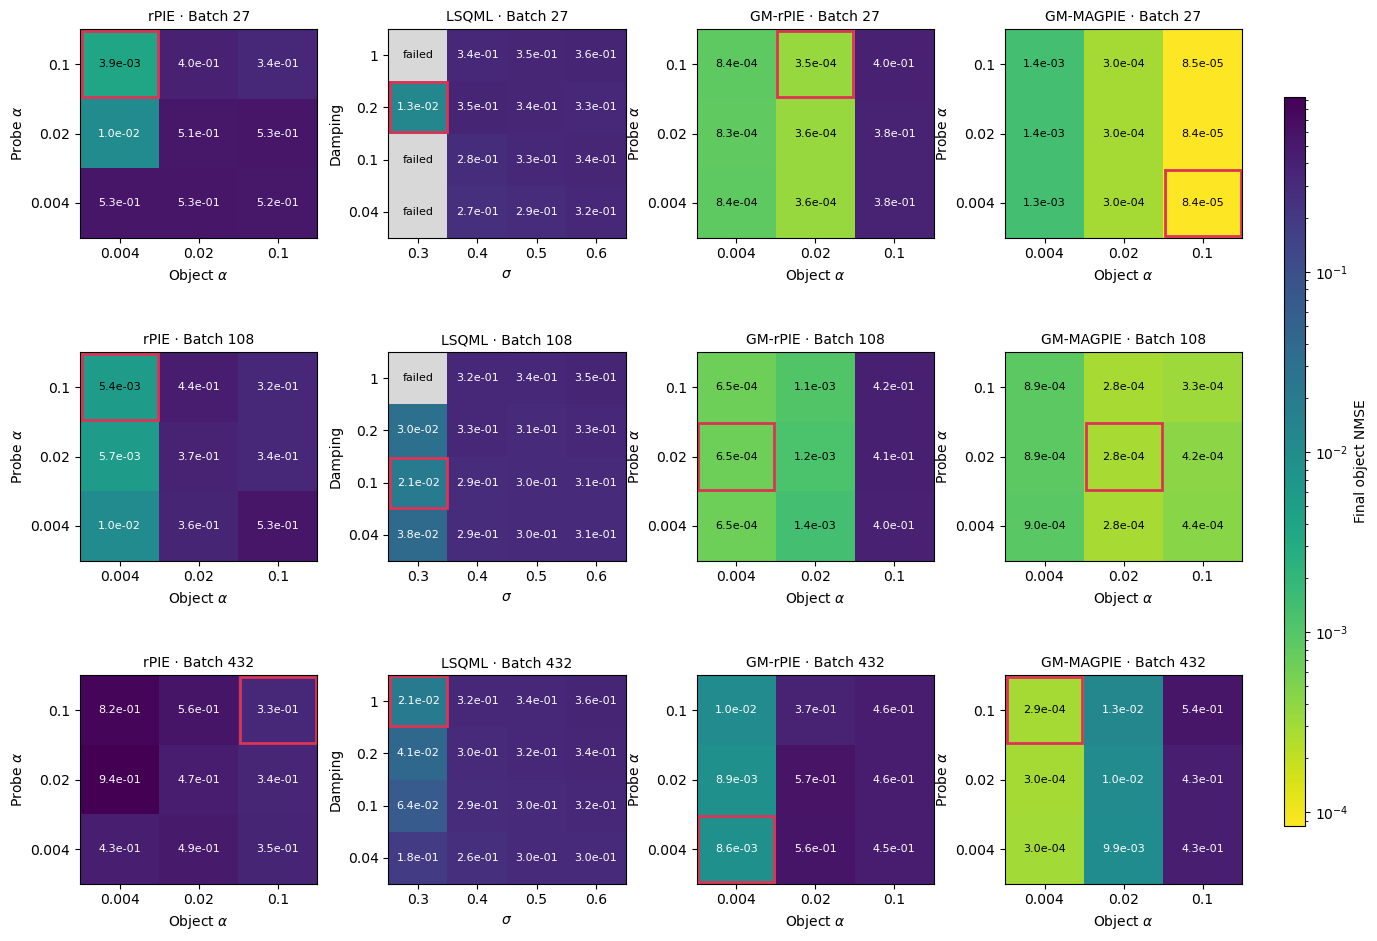

In [3]:
display(plot_sweep_heatmaps(STUDY))
plt.close("all")

## Object and probe convergence

The curves report normalized squared complex errors,
$\mathrm{NMSE}_X=\|X_{\mathrm{al}}-X^\star\|_2^2/\|X^\star\|_2^2$.
The object is aligned by a complex scale and affine phase ramp on the common scanned region. The probe uses the corresponding ambiguity correction and its remaining global phase is removed.


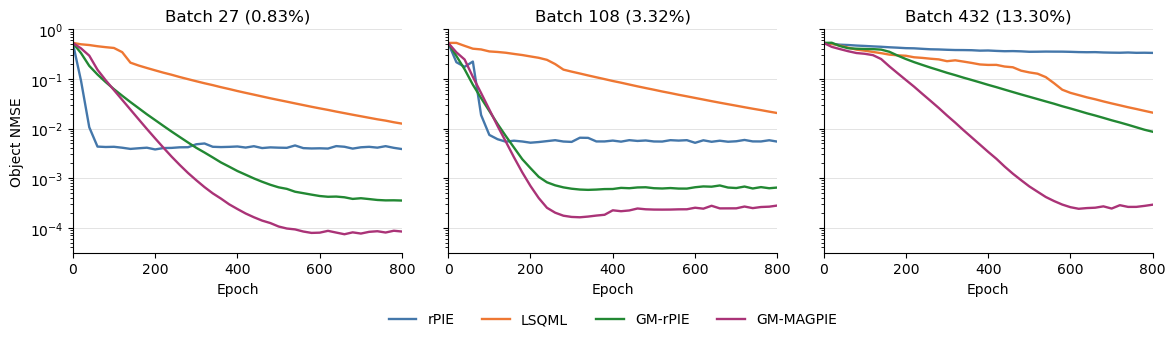

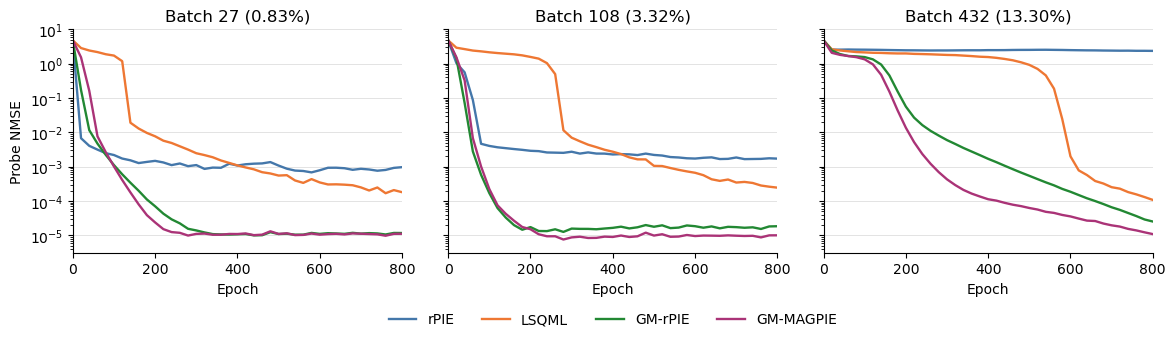

In [4]:
display(plot_convergence(STUDY, metric="object"))
display(plot_convergence(STUDY, metric="probe"))
plt.close("all")

## Reproduce the synthetic reconstructions

The cells above use the recorded results and run on CPU. To compute new reconstructions, install the reconstruction dependencies and use a CUDA GPU. Set the flag below to `True` to rerun the selected parameter pairs; new outputs go into `runs/`.


In [5]:
RUN_RECONSTRUCTIONS = False
if RUN_RECONSTRUCTIONS:
    from blind_magpie import run_experiments
    display(run_experiments(STUDY, mode="selected", output=ROOT / "runs"))
